In [ ]:
# Assemblage Google Drive dans Colaboratory
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
data=pd.read_csv('/content/drive/MyDrive/Salary_Data.csv', na_values=" ")#importation
data

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [ ]:
#dimension
data.shape

(30, 2)

In [ ]:
#noms des variables
data.columns

Index(['YearsExperience', 'Salary'], dtype='object')

In [ ]:
#nature des variables
data.dtypes

,0
YearsExperience,float64
Salary,float64


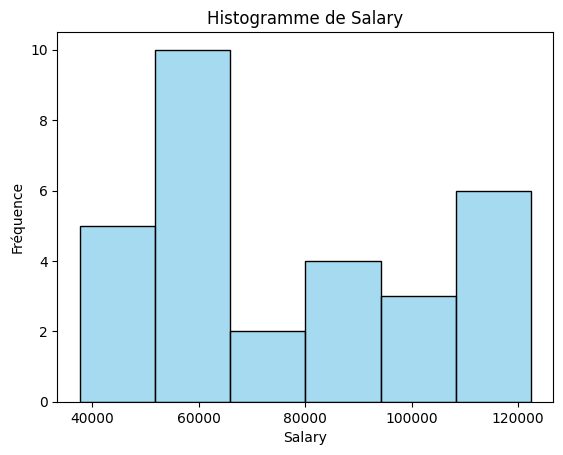

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data['Salary'], color='skyblue')
plt.title('Histogramme de Salary')
plt.xlabel('Salary')
plt.ylabel('Fréquence')

plt.show()


In [ ]:
#comparaison quantile Salary vs normal
from scipy import stats

for i in range (1,100): #par choix
  q=np.quantile(data['Salary'],i/100)


  q1=stats.norm.ppf(i/100,loc=data['Salary'].mean(),scale=data['Salary'].std())#normal
  print(i/100,q,q1,q-q1)

0.01 38198.48 12227.499552595065 25970.980447404938
0.02 38665.96 19700.644694321505 18965.315305678494
0.03 39133.44 24442.115690046332 14691.32430995367
0.04 39430.68 28008.939624811144 11421.740375188856
0.05 39589.6 30910.275738023323 8679.324261976675
0.06 39748.52 33379.768460001935 6368.751539998062
0.07 40000.020000000004 35545.03048126561 4454.989518734394
0.08 41053.88 37483.76436757808 3570.115632421919
0.09 42107.74 39246.965270574285 2860.7747294257133
0.1 43161.6 40869.994591056035 2291.605408943964
0.11 44034.2 42378.430974440635 1655.7690255593625
0.12 44811.4 43791.407091092566 1019.9929089074358
0.13 45588.6 45123.62948298942 464.9705170105808
0.14 46699.4 46386.66128630216 312.7387136978432
0.15 49089.0 47589.76961732586 1499.2303826741409
0.16 51478.6 48740.504187021885 2738.095812978114
0.17 53868.200000000004 49845.10366473546 4023.0963352645413
0.18 54741.78 50908.78807207517 3832.991927924828
0.19 55132.99 51935.97366117314 3197.0163388268556
0.2 55524.200000000

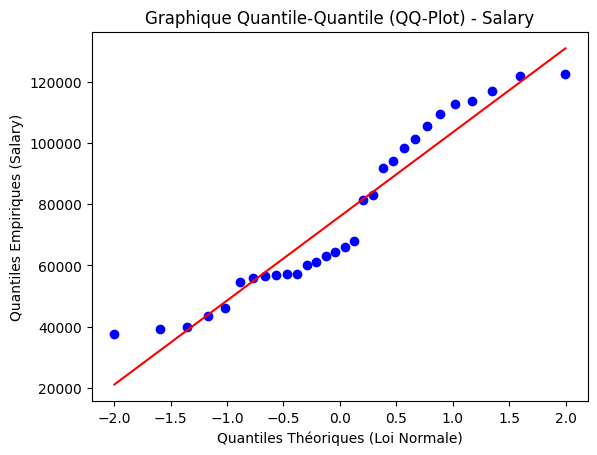

In [ ]:
#probplot salaire
stats.probplot(data['Salary'], dist='norm', plot=plt)
plt.title('Graphique Quantile-Quantile (QQ-Plot) - Salary')
plt.xlabel('Quantiles Théoriques (Loi Normale)')
plt.ylabel('Quantiles Empiriques (Salary)')
plt.show()
#la point bas est trés loin il ya aussi l'autre pt haut

In [ ]:
# Test de normalité de la variable Salary
import scipy.stats as stats
import matplotlib.pyplot as plt

# Shapiro
stat, p_value = stats.shapiro(data['Salary'])
print(f"Test de Shapiro :")
print(f"p-value = {p_value:.4f}")

if p_value > 0.05:
    print("distrubition de Salary normal.")
else:
    print("distrubition de Salary n'est pas normal.")


Test de Shapiro :
p-value = 0.0152
distrubition de Salary n'est pas normal.


Après suppression des 2 points extrêmes :
p-value = 0.0210
La distribution de Salary (sans les extrêmes) n'est pas normale.


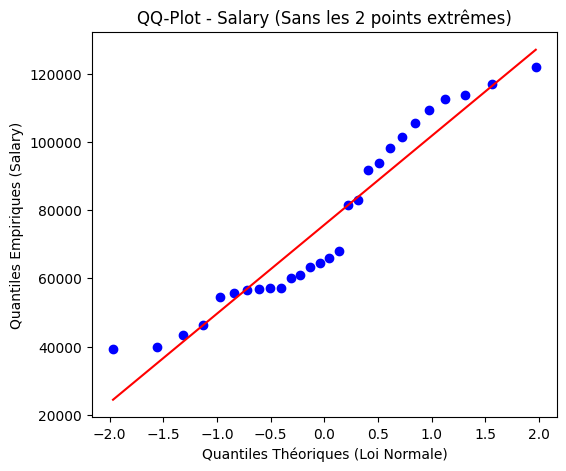

In [ ]:
#pourtant j'efface les pts a l'extrimité  il reste n'est pas normal il masse kbira de anormalité
import scipy.stats as stats
import matplotlib.pyplot as plt

# Identifier les index du minimum et du maximum pour 'Salary'
id_min = data['Salary'].idxmin()
id_max = data['Salary'].idxmax()

# Supprimer ces deux points
data_cleaned = data.drop(index=[id_min, id_max])

# Nouveau test de Shapiro sur les données nettoyées
stat_clean, p_value_clean = stats.shapiro(data_cleaned['Salary'])
print("Après suppression des 2 points extrêmes :")
print(f"p-value = {p_value_clean:.4f}")
if p_value_clean > 0.05:
    print("La distribution de Salary (sans les extrêmes) est normale.")
else:
    print("La distribution de Salary (sans les extrêmes) n'est pas normale.")

# Nouveau Q-Q Plot
plt.figure(figsize=(6, 5))
stats.probplot(data_cleaned['Salary'], dist='norm', plot=plt)
plt.title('QQ-Plot - Salary (Sans les 2 points extrêmes)')
plt.xlabel('Quantiles Théoriques (Loi Normale)')
plt.ylabel('Quantiles Empiriques (Salary)')
plt.show()

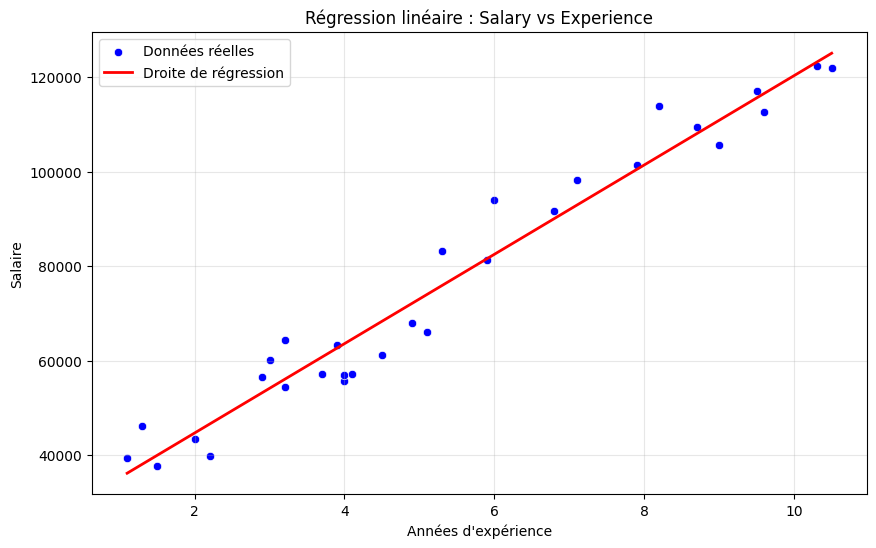

In [ ]:
#outil graphique pour connaitre si modele cv ou nn

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Préparation des variables
X = data[['YearsExperience']]
y = data['Salary']

# Création et entraînement du modèle
model = LinearRegression()
model.fit(X, y)

# Prédiction
y_pred = model.predict(X)

# Graphique d'évaluation
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=data['YearsExperience'],
    y=data['Salary'],
    color='blue',
    label='Données réelles'
)

plt.plot(
    data['YearsExperience'],
    y_pred,
    color='red',
    linewidth=2,
    label='Droite de régression'
)

plt.title('Régression linéaire : Salary vs Experience')
plt.xlabel("Années d'expérience")
plt.ylabel('Salaire')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Lambda optimal trouvé pour Box-Cox : 0.0728


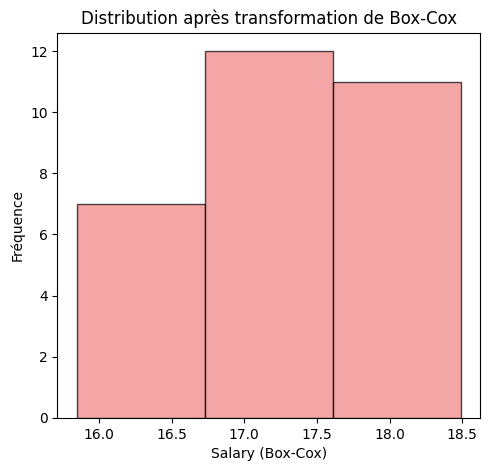

In [ ]:
from scipy import stats
import matplotlib.pyplot as plt

# Application de la transformation de Box-Cox sur la colonne 'Salary'
# Note : Box-Cox nécessite des valeurs strictement positives, ce qui est le cas pour les salaires.
data['Salary_BoxCox'], fitted_lambda = stats.boxcox(data['Salary'])

print(f"Lambda optimal trouvé pour Box-Cox : {fitted_lambda:.4f}")

# Visualisation de la distribution après la transformation
plt.figure(figsize=(12, 5))

# Histogramme des données transformées
plt.subplot(1, 2, 1)
plt.hist(data['Salary_BoxCox'], bins=3, color='lightcoral', edgecolor='black', alpha=0.7)
plt.title('Distribution après transformation de Box-Cox')
plt.xlabel('Salary (Box-Cox)')
plt.ylabel('Fréquence')
plt.show()# == decale a droite

In [ ]:
from sklearn.model_selection import train_test_split # train_test_split hedhi fonction
from sklearn.linear_model import LinearRegression #LinearRegression classe
from sklearn.metrics import mean_squared_error, r2_score

erreur0 = 10000
regressor = LinearRegression()

for i in range(15,31):
    for j in range(0,1001):

        # Définition des variables explicatives (X) et de la variable cible (y)
        # Nous utilisons ici 'Salary' brut, mais vous pouvez aussi utiliser 'Salary_BoxCox' selon vos besoins
        X = data[['YearsExperience']]
        y = data['Salary']

        # Division des données : 80% entraînement, 20% test
        #fix random_state = j ()
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=i/100, random_state=j)



        # 2. Entraînement du modèle sur les données d'entraînement
        regressor.fit(X_train, y_train)

        # 3. Prédictions sur l'ensemble de test
        y_pred_test = regressor.predict(X_test)

        # error
        mse = mean_squared_error(y_test, y_pred_test)

        # unité au carré donc bech nahiw au carré
        erreur = mse**0.5

        #print(i/100,erreur, erreur / y_test.std()) #akbar mn 5% barcha sinon negligeable*
        #compare (okher affichage )
        if erreur < erreur0:
            erreur0 = erreur
            i_final = i
            j_final = j
            y_test_final = y_test

            print(i_final, j_final, erreur0, erreur0 / y_test_final.std())

15 0 3844.94575472938 0.10135906992122909
15 3 2533.435221415621 0.10350980622028885
15 10 2224.0794134413327 0.10584598124612941
15 30 2145.8912295473415 0.07612235548754928
15 39 1619.179272997306 0.05902325166508305
15 543 1209.539750338364 0.03683189619662433
